Choose a sample to run. `sample_id` can be one of:
- mouse_vas_deferens1
- mouse_vas_deferens2
- mouse_femoral_artery
- mouse_bladder
- mouse_trachea
- human_cornea
- insect_leg

In [ ]:
max_angle = 30
interval = 6
n_bscans = int(max_angle/interval)*2+1
anglename = str(max_angle) + '-' + str(interval) + '-' + str(max_angle)

# sample_id = 'mouse_vas_deferens1'  # a string that denotes which data to run
sample_id = 'phantom'  # a string that denotes which data to run

data_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/Datasets/' + anglename + '/'  # where is the OCRT input data located?
save_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/' + anglename + '/'  # where to save the tf graph after optimization

# Registration of multiangle B-scans and synthesis of refractive index map
The registration metric is optimized with respect to the deformation model, which in this case is ray propagation through a spatially inhomogeneous refractive index map.

In [2]:
from __future__ import print_function, division
import OCRT
import importlib
importlib.reload(OCRT)
from OCRT import OCRT2D
import numpy as np

import tensorflow as tf
tf.compat.v1.disable_eager_execution()
import matplotlib.pyplot as plt
import numpy as np
from time import time
%matplotlib inline

a = OCRT2D(sample_id=sample_id,save_directory=save_directory)

In [ ]:
# adjust some parameters, depending on the sample:
if sample_id in ['mouse_bladder', 'mouse_femoral_artery', 'mouse_trachea', 'mouse_vas_deferens1']:
    num_iter = 200
elif sample_id in ['mouse_vas_deferens2']:
    num_iter = 300
elif sample_id in ['insect_leg']:
    num_iter = 500
elif sample_id in ['human_cornea']:
    num_iter = 500
    # this sample is more difficult to register, so use a multiresolution approach:
    a.use_multires = True
    a.size_factor_ = 1  # the final size_factor_ is 8
    a.switch_iter = 250
elif sample_id in ['phantom']:
    num_iter = 1
else:
    raise Exception('invalid sample_id: ' + sample_id)
    
# two tube sizes were used (same inner diameter, but different outer diameter):
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066  # in mm
elif sample_id in ['phantom']:
    a.tube_diameter = 0
    a.tube_present = False
    a.knownRI = True
    a.use_parametric_optimization = False
    a.n_back = 1
    a.use_spatial_shifts = False
else:
    a.tube_diameter = 1.108516

In [4]:
a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 2.03950834274292 sec
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
graph built: 6.577648639678955 sec


0 [1.2647231, 0.0, 0.0005770487] 19.411810874938965
0


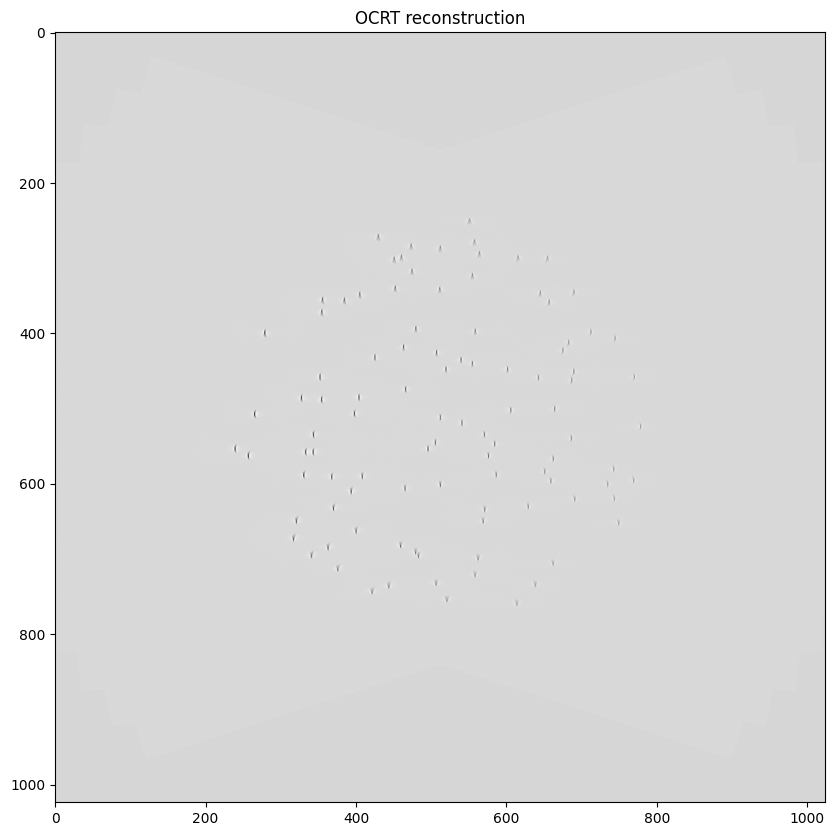

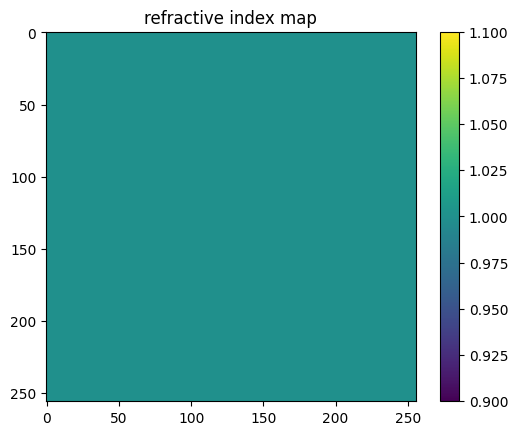

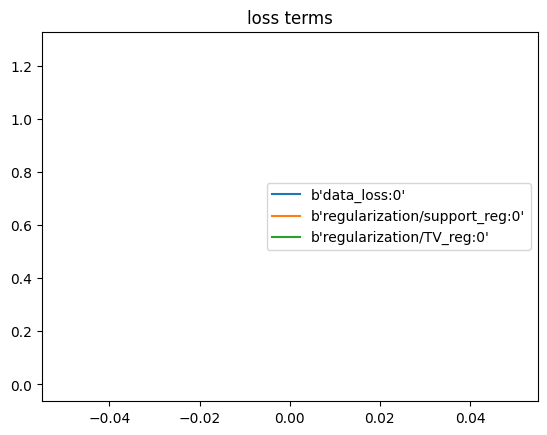

1 [1.2575147, 0.0, 0.0005770487] 16.736880779266357
1
2 [1.2506198, 0.0, 0.0005770487] 16.41486167907715
2
3 [1.2440331, 0.0, 0.0005770487] 17.36402130126953
3
4 [1.237749, 0.0, 0.0005770487] 17.04305648803711
4
5 [1.2317617, 0.0, 0.0005770487] 17.21723699569702
5
6 [1.2260658, 0.0, 0.0005770487] 16.640610933303833
6
7 [1.2206538, 0.0, 0.0005770487] 17.17561149597168
7
8 [1.2155155, 0.0, 0.0005770487] 17.426555633544922
8
9 [1.2106372, 0.0, 0.0005770487] 17.375963926315308
9
10 [1.2059984, 0.0, 0.0005770487] 18.254469394683838
10


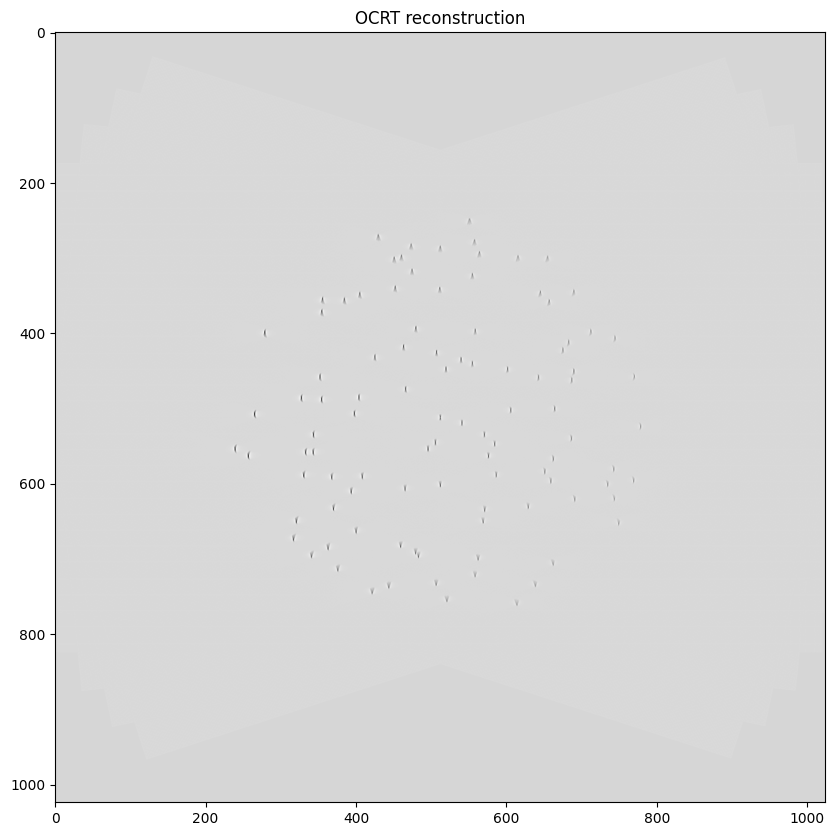

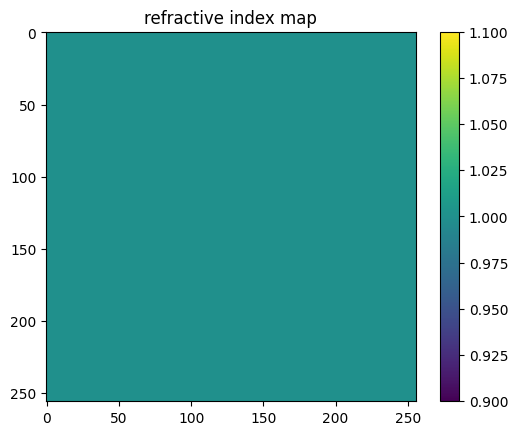

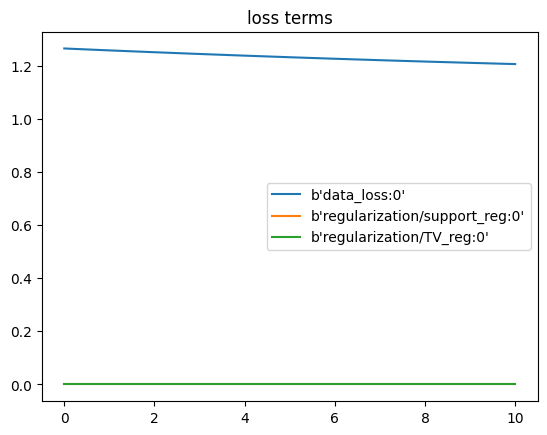

11 [1.2015735, 0.0, 0.0005770487] 16.967288732528687
11
12 [1.1973299, 0.0, 0.0005770487] 17.229727268218994
12
13 [1.1932299, 0.0, 0.0005770487] 18.67147970199585
13
14 [1.1892309, 0.0, 0.0005770487] 16.89263153076172
14
15 [1.1852875, 0.0, 0.0005770487] 17.89131808280945
15
16 [1.1813513, 0.0, 0.0005770487] 18.202660083770752
16
17 [1.1773746, 0.0, 0.0005770487] 17.37496829032898
17
18 [1.173311, 0.0, 0.0005770487] 18.001702547073364
18
19 [1.1691176, 0.0, 0.0005770487] 17.73142910003662
19
20 [1.1647551, 0.0, 0.0005770487] 18.368645429611206
20


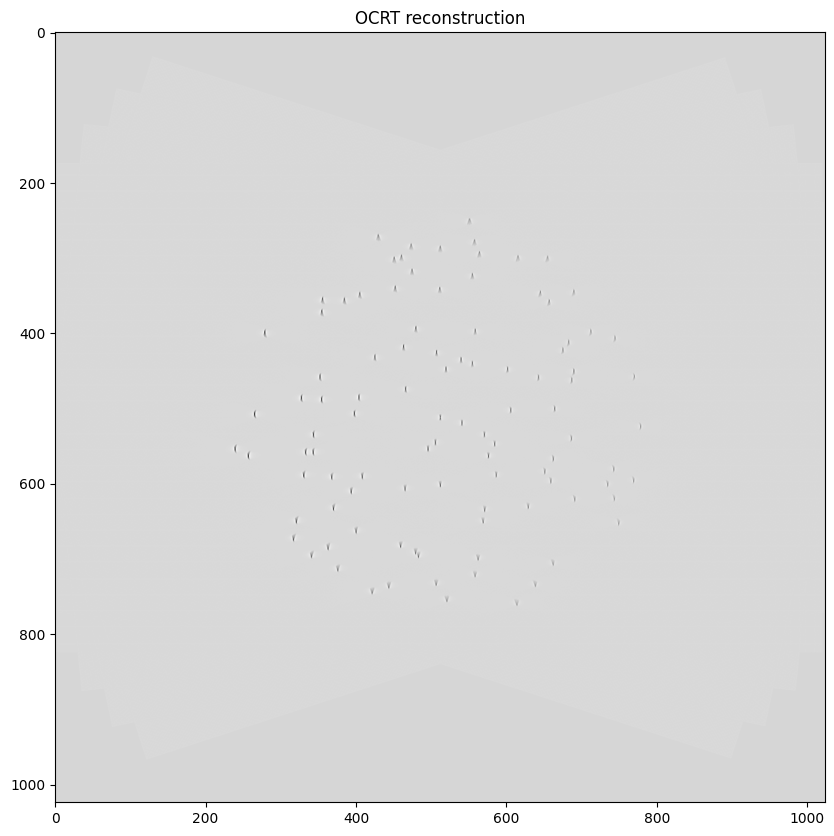

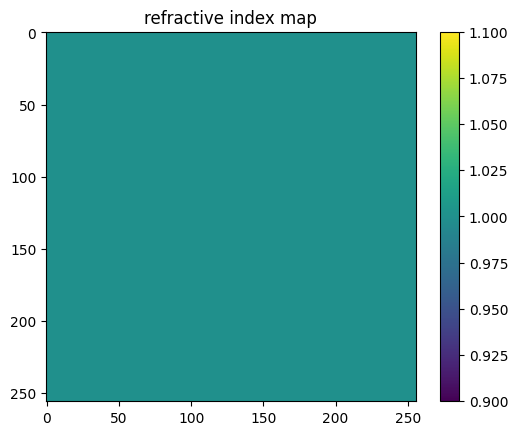

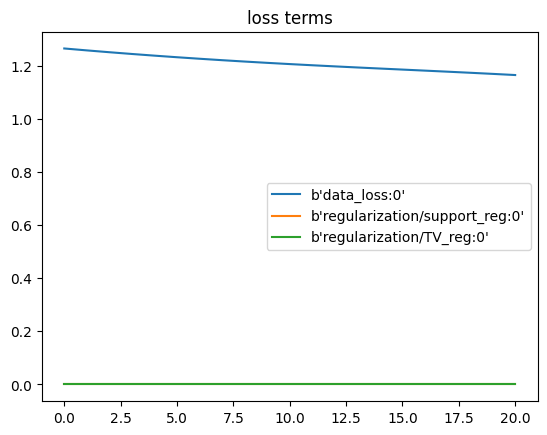

21 [1.1601887, 0.0, 0.0005770487] 17.644200801849365
21
22 [1.1553874, 0.0, 0.0005770487] 17.753649711608887
22
23 [1.1503242, 0.0, 0.0005770487] 17.495922088623047
23
24 [1.1449744, 0.0, 0.0005770487] 18.06821608543396
24
25 [1.1393158, 0.0, 0.0005770487] 18.089496612548828
25
26 [1.1333294, 0.0, 0.0005770487] 18.997427463531494
26
27 [1.1269952, 0.0, 0.0005770487] 19.18465781211853
27
28 [1.1202964, 0.0, 0.0005770487] 18.697926998138428
28
29 [1.1132154, 0.0, 0.0005770487] 19.253663539886475
29
30 [1.1057358, 0.0, 0.0005770487] 18.54136824607849
30


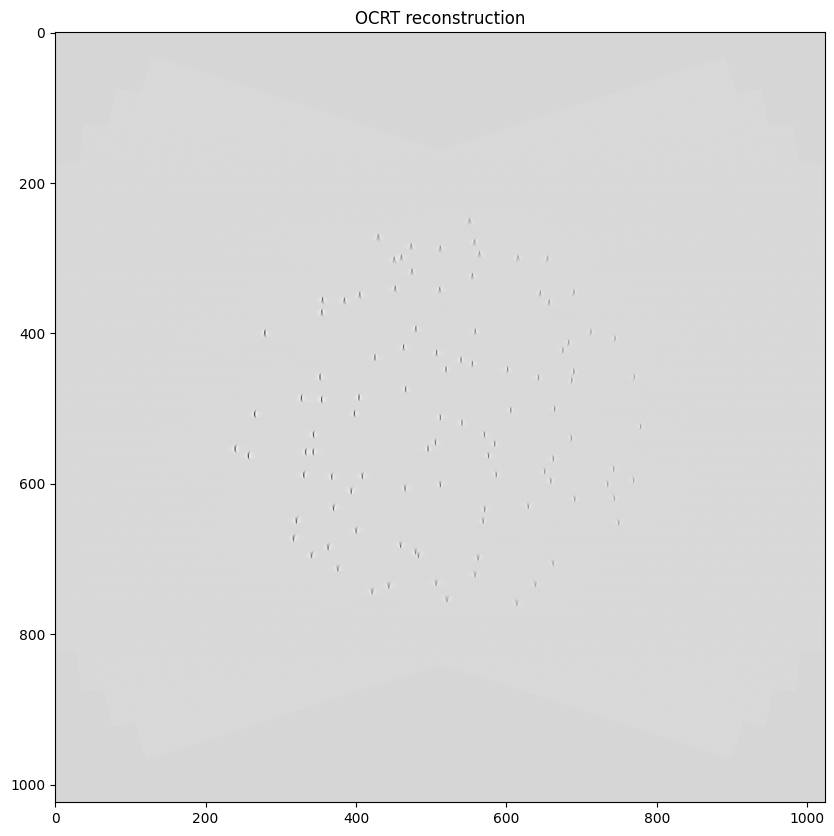

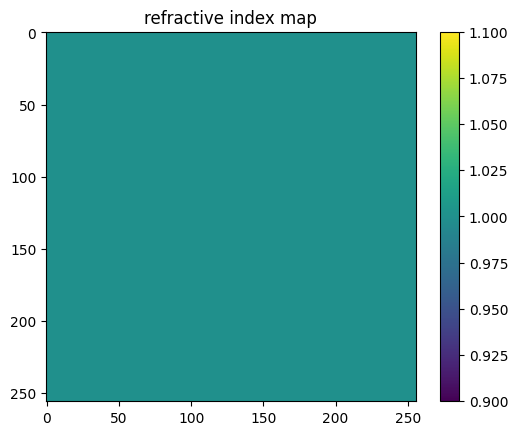

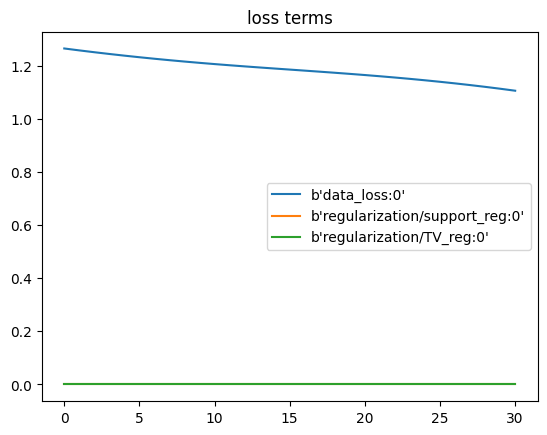

31 [1.097842, 0.0, 0.0005770487] 19.18819761276245
31
32 [1.0895177, 0.0, 0.0005770487] 19.058842182159424
32
33 [1.0807482, 0.0, 0.0005770487] 19.053715705871582
33
34 [1.0715188, 0.0, 0.0005770487] 18.927836656570435
34
35 [1.0618147, 0.0, 0.0005770487] 19.391499280929565
35
36 [1.0516225, 0.0, 0.0005770487] 18.88641381263733
36
37 [1.0409287, 0.0, 0.0005770487] 18.90360736846924
37
38 [1.029722, 0.0, 0.0005770487] 18.281063079833984
38
39 [1.0179899, 0.0, 0.0005770487] 17.534935235977173
39
40 [1.0057226, 0.0, 0.0005770487] 17.444745779037476
40


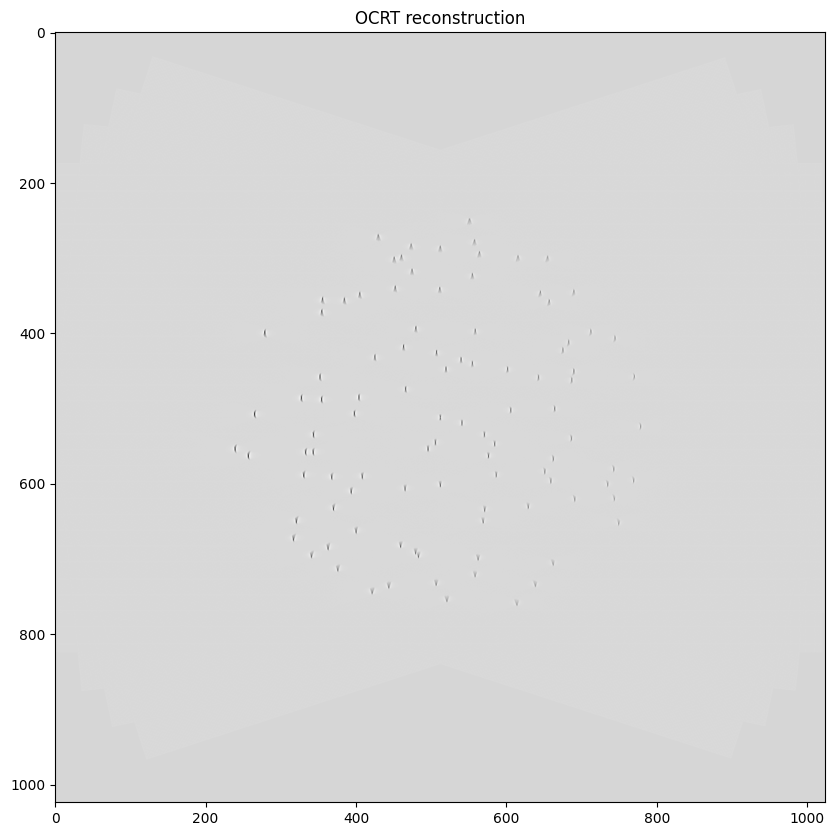

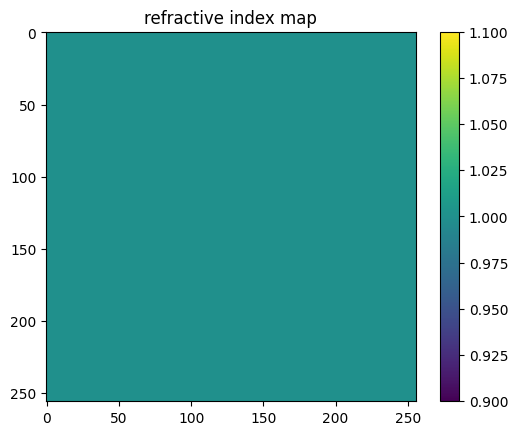

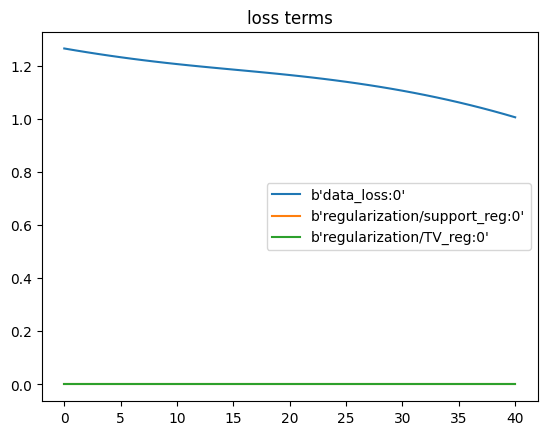

41 [0.99290854, 0.0, 0.0005770487] 17.903764247894287
41
42 [0.9795445, 0.0, 0.0005770487] 18.623459339141846
42
43 [0.9656166, 0.0, 0.0005770487] 17.668975353240967
43
44 [0.9511244, 0.0, 0.0005770487] 18.241026639938354
44
45 [0.9360636, 0.0, 0.0005770487] 18.24486517906189
45
46 [0.9204269, 0.0, 0.0005770487] 18.00387406349182
46
47 [0.9042185, 0.0, 0.0005770487] 18.388460397720337
47
48 [0.88743806, 0.0, 0.0005770487] 17.482277870178223
48
49 [0.87009186, 0.0, 0.0005770487] 16.940207481384277
49
50 [0.8521819, 0.0, 0.0005770487] 18.535977363586426
50


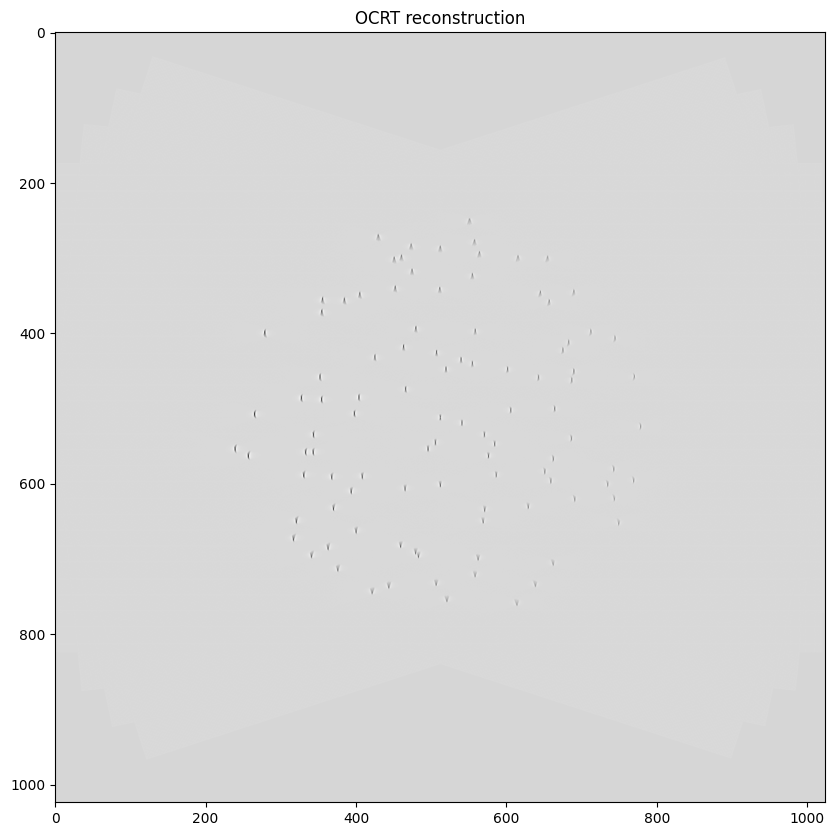

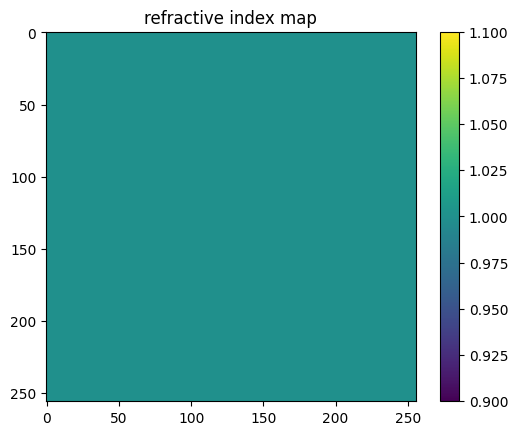

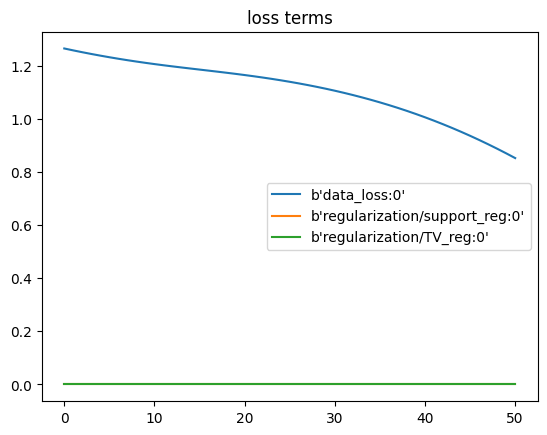

In [5]:
# run through optimization loop:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    
    # if using multires, change the pixel resolution of the reconstruction
    if i == a.switch_iter and a.use_multires: 
        feed_dict[a.size_factor] = a.final_size_factor
    
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    # loss_i is a list of all the contributors to the scalar loss;
    # (see a.loss_terms or a.loss_term_names for names of the regularization terms)
    print(i)
    # monitor results periodically:
    if i % 10 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)  # only once slice along y contains nonzero values, because we are optimizing 2D
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        RI = a.sess.run(a.RI, feed_dict={a.xz_delta: np.zeros((n_bscans, 2))})  # remove xy_delta shifts
        
        plt.imshow(RI)
        plt.title('refractive index map')
        plt.colorbar()
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [6]:
a.save_graph()  # this graph must be saved in order to run filter optimization below

# Filter optimization after registration
Freeze the registration/refractive index parameters and only optimize the 2D backprojection filter.

In [7]:
# remove previous tf graph and variables:
a.sess.close()
tf.compat.v1.reset_default_graph()
del a

In [8]:
# # Run during debugs when OCRT.py has been changed
# import OCRT
# import importlib
# importlib.reload(OCRT)
# from OCRT import OCRT2D

In [9]:
# instantiate new object, this time for filter optimization
a = OCRT2D(sample_id=sample_id,save_directory=save_directory)
num_iter = 100
a.infer_backprojection_filter = True
a.use_spatial_shifts = False

# as above, set the tube diameter depending on the sample:
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066
elif sample_id in ['phantom']:
    a.tube_diameter = 0
    a.tube_present = False
    a.knownRI = True
    a.use_parametric_optimization = False
    a.n_back = 1.35 
else:
    a.tube_diameter = 1.108516

a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 2.3006134033203125 sec
INFO:tensorflow:Restoring parameters from c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/18-6-18/phantom/model.ckpt
graph built: 8.178822040557861 sec


0 [0.8337034, 0.0007858621] 25.863293886184692


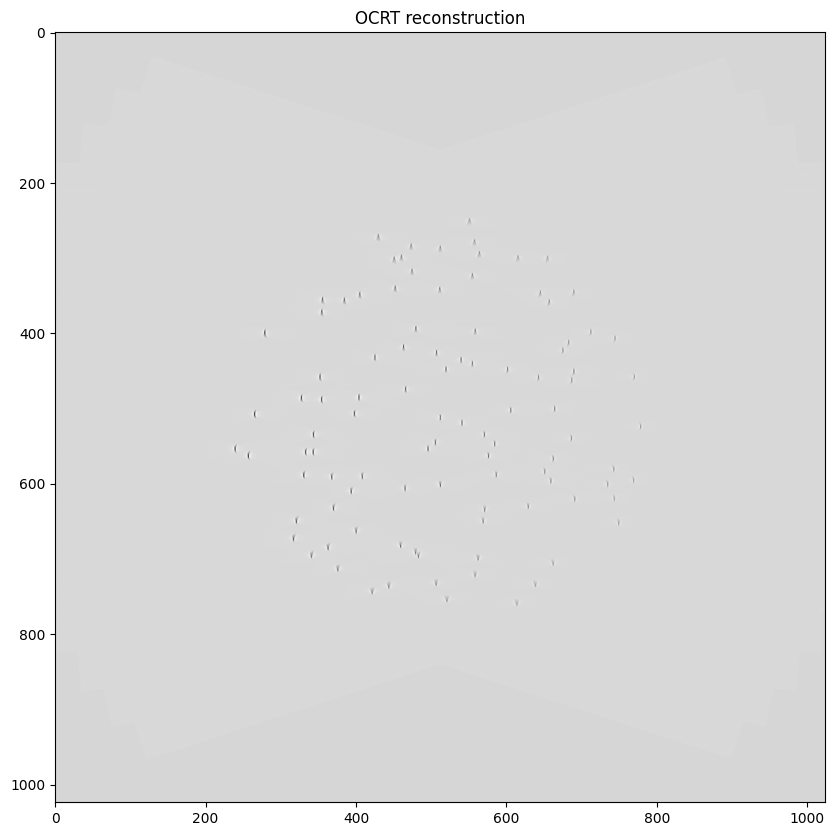

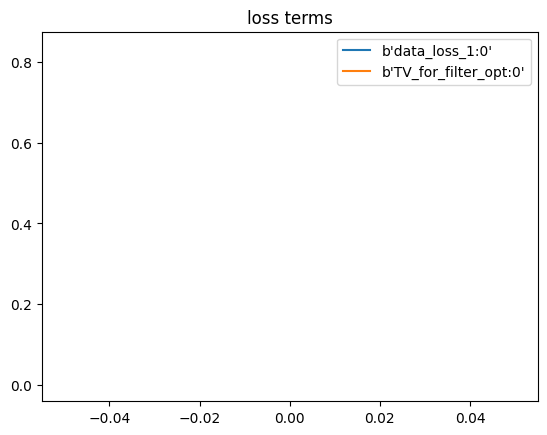

1 [0.82399535, 0.0007729287] 23.42151975631714
2 [0.81434774, 0.00075999746] 24.133074283599854
3 [0.8047726, 0.000747116] 23.65558958053589
4 [0.79530823, 0.0007343109] 24.06606411933899
5 [0.78590965, 0.00072160223] 24.00899863243103
6 [0.7765887, 0.0007090078] 23.342096090316772
7 [0.7673464, 0.0006965441] 24.023566961288452
8 [0.75816596, 0.00068422913] 23.86049509048462
9 [0.74908644, 0.0006720835] 23.946027517318726
10 [0.7400292, 0.00066012895] 23.18243932723999
11 [0.7310926, 0.00064839213] 23.844877243041992
12 [0.72226435, 0.00063690345] 23.95942258834839
13 [0.71355844, 0.0006256993] 24.133050441741943
14 [0.70489264, 0.00061482005] 23.473209381103516
15 [0.6963253, 0.0006043156] 23.8806471824646
16 [0.68798417, 0.00059425255] 23.76849865913391
17 [0.67961305, 0.00058471673] 23.186214685440063
18 [0.671246, 0.0005758265] 23.68326473236084
19 [0.6628602, 0.00056774396] 23.44257616996765
20 [0.6545305, 0.00056069624] 23.529770135879517


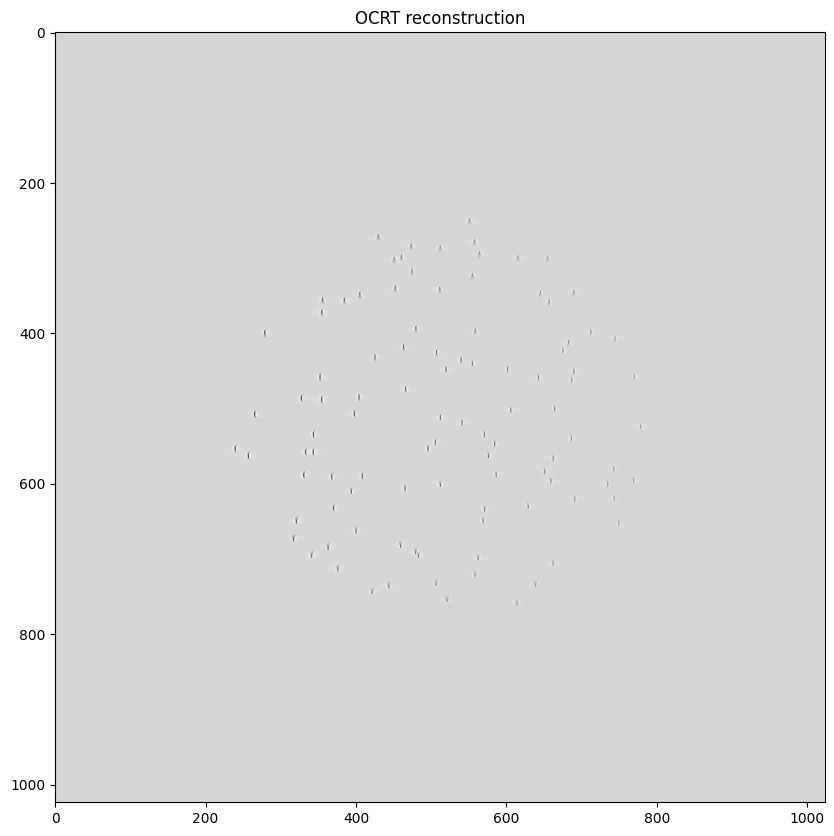

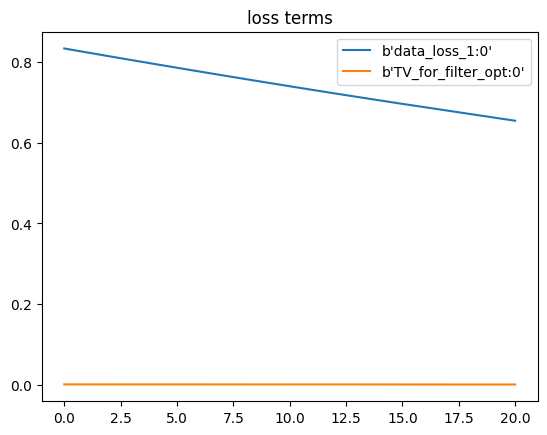

21 [0.64628255, 0.00055511756] 23.176048755645752
22 [0.6380773, 0.00055224536] 23.851791858673096
23 [0.629953, 0.00055319763] 23.93173384666443
24 [0.6218978, 0.00055721164] 23.911409616470337
25 [0.61390835, 0.00056289724] 23.197606325149536
26 [0.6059944, 0.0005696546] 23.787969827651978
27 [0.5981522, 0.0005771809] 23.30836296081543
28 [0.59039396, 0.0005852908] 24.003963947296143
29 [0.5827026, 0.00059385115] 23.497612476348877
30 [0.5750849, 0.0006027634] 23.384124279022217
31 [0.5675401, 0.00061195315] 24.13100028038025
32 [0.5600783, 0.00062136323] 24.32139229774475
33 [0.55268115, 0.0006309491] 24.116118907928467
34 [0.54535764, 0.00064067566] 24.005704402923584
35 [0.53811175, 0.0006505148] 24.071946620941162
36 [0.5309362, 0.0006604436] 24.682922840118408
37 [0.5238432, 0.0006704437] 24.911219835281372
38 [0.5168178, 0.0006804999] 23.975138902664185
39 [0.5098711, 0.0006905992] 23.7029390335083
40 [0.50298655, 0.0007007311] 24.05772352218628


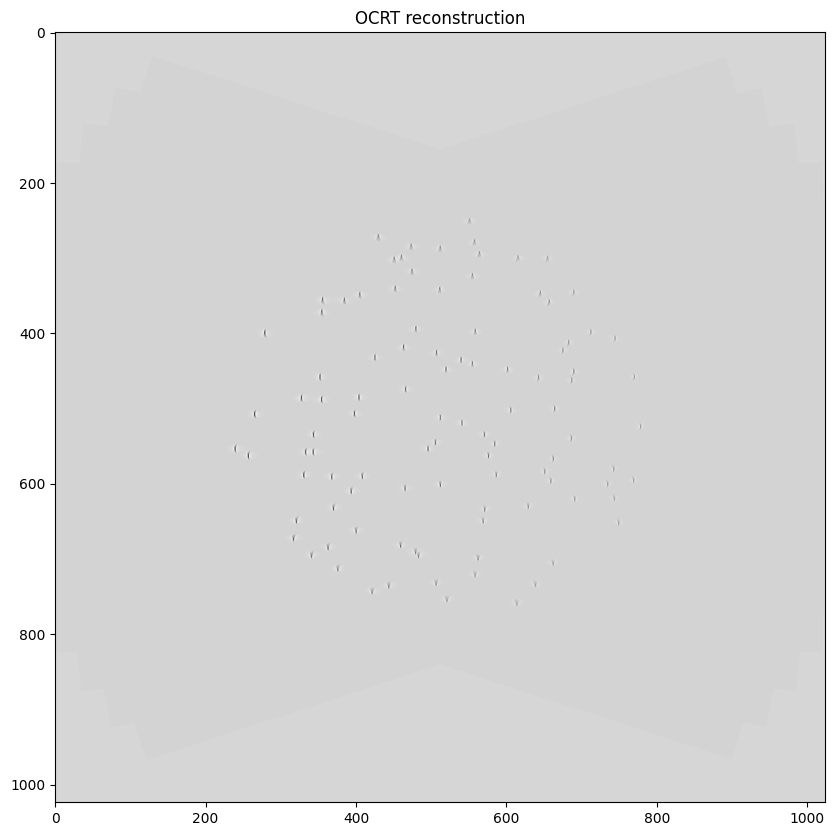

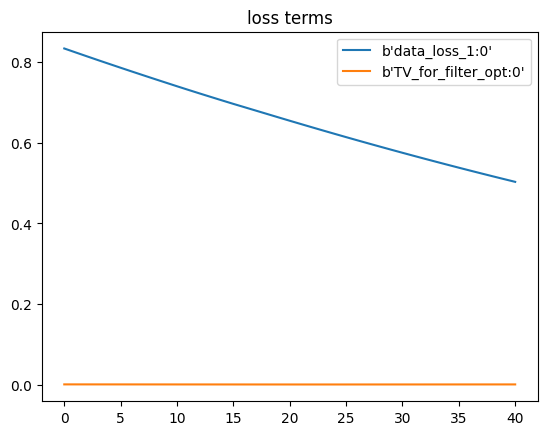

41 [0.49617425, 0.0007108868] 23.830593585968018
42 [0.48943275, 0.00072105846] 23.800368309020996
43 [0.48276, 0.0007312397] 23.953876733779907
44 [0.4761622, 0.00074142485] 24.713620901107788
45 [0.4696317, 0.000751609] 24.111214876174927
46 [0.46318287, 0.0007617876] 23.752016067504883
47 [0.4568012, 0.0007719568] 24.392906427383423
48 [0.45049214, 0.00078211346] 24.10577702522278
49 [0.44424975, 0.00079225434] 24.350780725479126
50 [0.43808416, 0.0008023769] 24.382702589035034
51 [0.43197942, 0.0008124786] 23.86770248413086
52 [0.4259482, 0.00082255725] 23.995590686798096
53 [0.41998193, 0.0008326108] 23.73735284805298
54 [0.4140769, 0.0008426379] 23.34349799156189
55 [0.40825075, 0.00085263624] 23.810954332351685
56 [0.4024808, 0.0008626048] 25.040883541107178
57 [0.39678252, 0.00087254227] 24.230598211288452
58 [0.39114642, 0.00088244735] 24.73779582977295
59 [0.38558185, 0.00089231884] 23.990673303604126
60 [0.38007304, 0.0009021556] 23.871392965316772


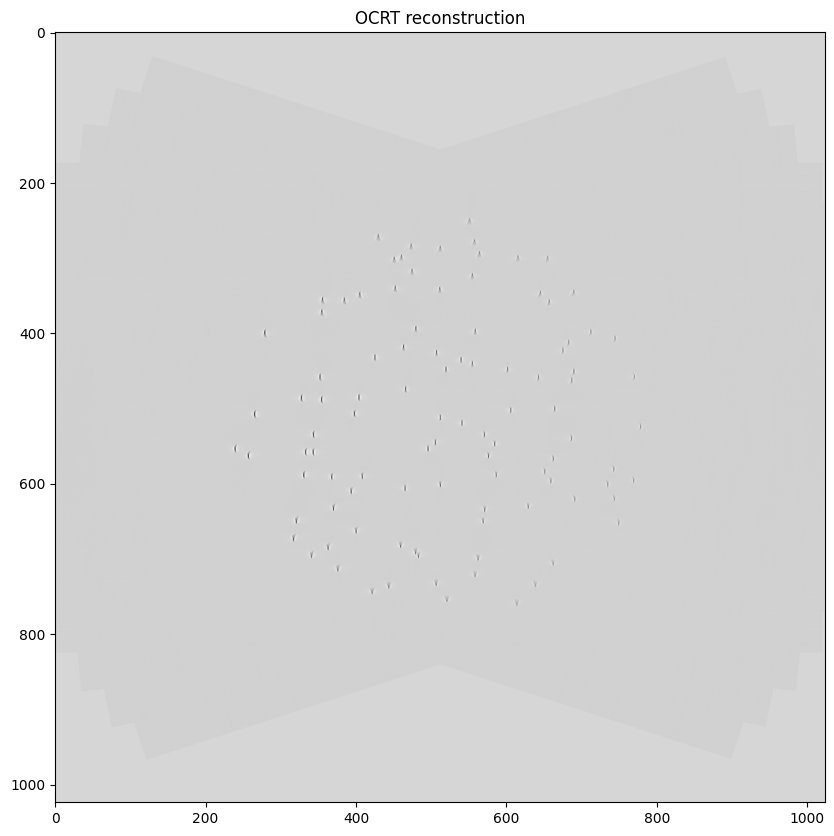

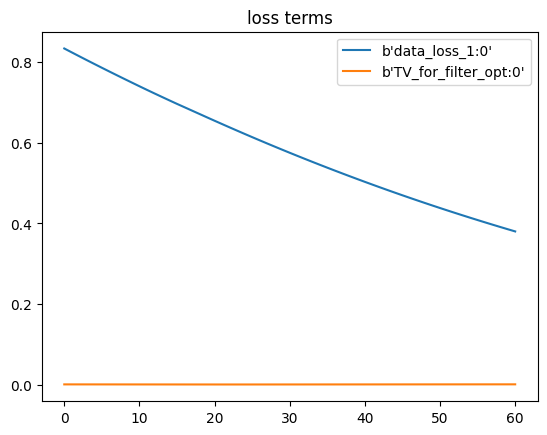

61 [0.3746361, 0.00091195654] 24.302555084228516
62 [0.36925808, 0.00092172093] 24.097386598587036
63 [0.36396176, 0.0009314478] 23.633485555648804
64 [0.35871282, 0.0009411363] 23.87440824508667
65 [0.35352826, 0.00095078605] 24.05750823020935
66 [0.34839892, 0.000960396] 23.78752875328064
67 [0.34334403, 0.0009699658] 23.70670461654663
68 [0.33835143, 0.0009794949] 23.82945418357849
69 [0.33341813, 0.000988983] 23.847151041030884
70 [0.32853615, 0.0009984293] 24.05267572402954
71 [0.32372916, 0.0010078334] 24.265166759490967
72 [0.31897247, 0.0010171948] 24.09614086151123
73 [0.3142805, 0.0010265138] 24.015665292739868
74 [0.30964246, 0.0010357893] 23.98970627784729
75 [0.30507895, 0.001045021] 23.321570873260498
76 [0.30057898, 0.0010542087] 24.366518259048462
77 [0.29612002, 0.0010633522] 23.57062339782715
78 [0.29172412, 0.0010724511] 24.445661306381226
79 [0.28737718, 0.0010815052] 23.713210821151733
80 [0.28309, 0.0010905142] 23.76968288421631


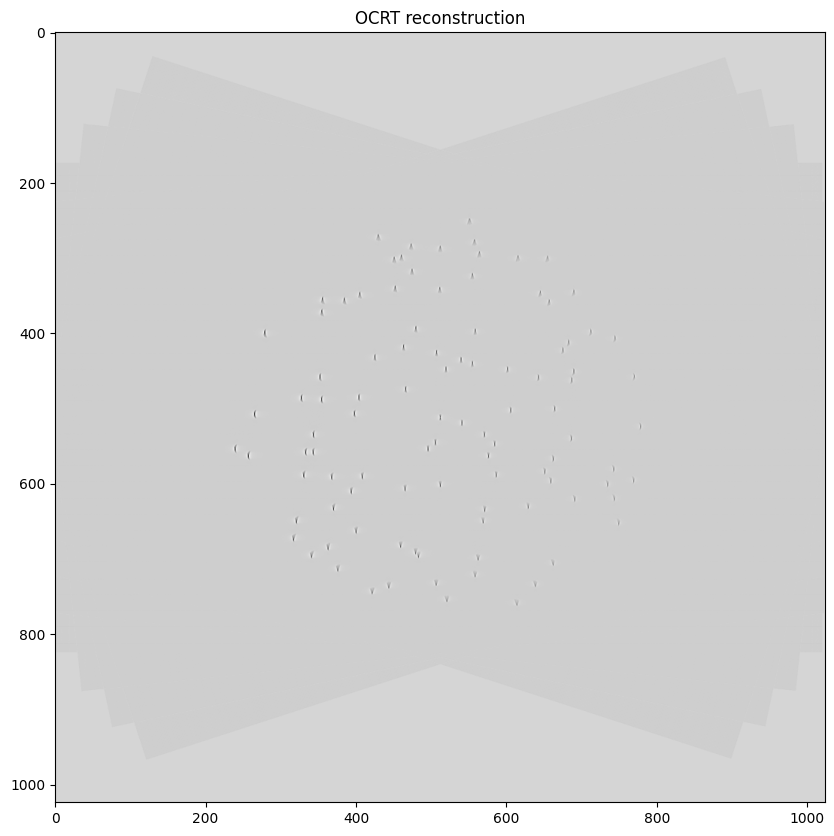

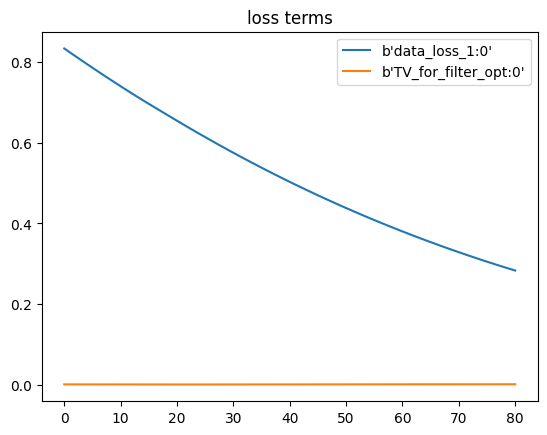

81 [0.27885914, 0.0010994781] 24.04469633102417
82 [0.2746934, 0.0011083964] 24.419918060302734
83 [0.2705754, 0.0011172694] 24.301881074905396
84 [0.2665214, 0.0011260964] 23.468902587890625
85 [0.2625096, 0.0011348766] 23.6955988407135
86 [0.25856045, 0.0011436108] 23.12452006340027
87 [0.25466344, 0.0011522983] 23.09398317337036
88 [0.2508151, 0.001160939] 24.772706747055054
89 [0.24701056, 0.0011695327] 24.229192972183228
90 [0.24327351, 0.0011780798] 24.950140237808228
91 [0.23957895, 0.0011865795] 23.52910876274109
92 [0.23593324, 0.0011950321] 24.46053457260132
93 [0.23232846, 0.0012034372] 24.027655601501465
94 [0.22877856, 0.0012117949] 24.217018127441406
95 [0.22528438, 0.0012201052] 24.53766894340515
96 [0.2218276, 0.0012283679] 24.264546632766724
97 [0.21842653, 0.0012365828] 24.35425591468811
98 [0.21506913, 0.00124475] 24.221216201782227
99 [0.21176693, 0.0012528694] 23.552690982818604
100 [0.20850806, 0.0012609411] 24.151688814163208


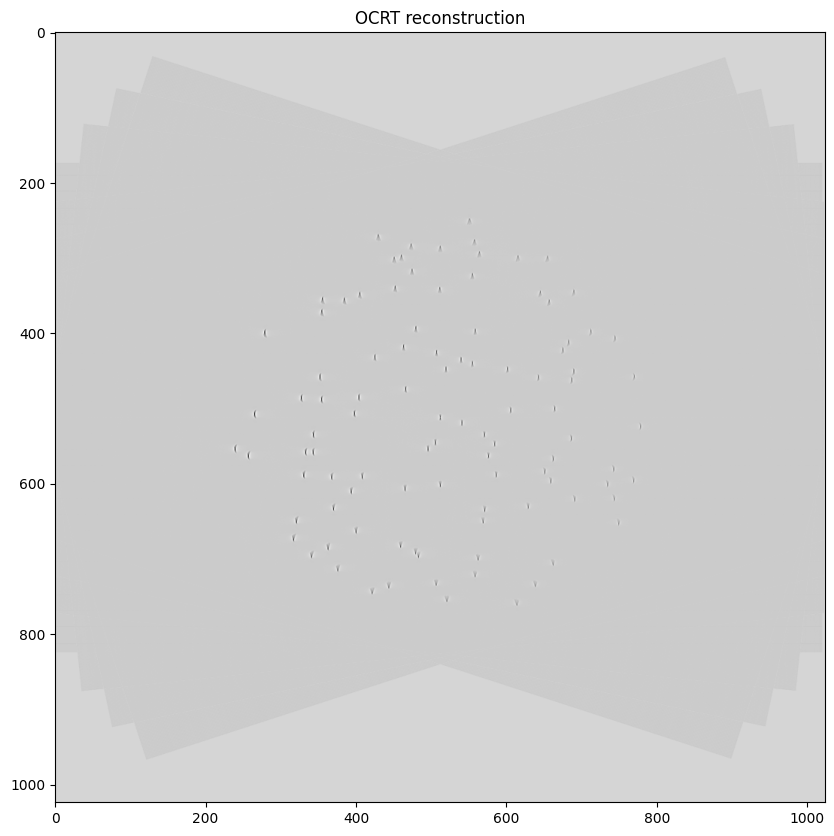

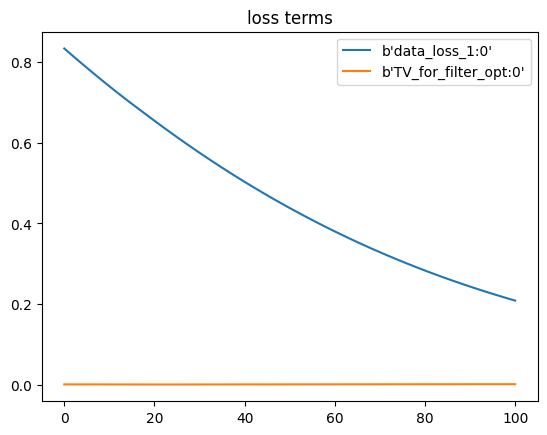

In [10]:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    
    # monitor results periodically:
    if i % 20 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [11]:
a.save_graph()  # this graph doesn't need to be saved